In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score 
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt
from sklearn.utils import shuffle 
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler

In [2]:
churn_data = pd.read_csv('data/Churn.csv')

Looking at data types and details of the dataset

In [3]:
#checking basic information about data in the columns.  I notice
#the Tenure column has 9091 non-null values, it is missing 909
#non-null values.
churn_data.head()
churn_data.info()
churn_data.shape
churn_data.dtypes

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           9091 non-null   float64
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(3), int64(8), str(3)
memory usage: 1.1 MB


RowNumber            int64
CustomerId           int64
Surname                str
CreditScore          int64
Geography              str
Gender                 str
Age                  int64
Tenure             float64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object

In [4]:
churn_data['Tenure'].head(10)

0    2.0
1    1.0
2    8.0
3    1.0
4    2.0
5    8.0
6    7.0
7    4.0
8    4.0
9    2.0
Name: Tenure, dtype: float64

In [5]:
#checking null values
churn_data.isnull().sum()

RowNumber            0
CustomerId           0
Surname              0
CreditScore          0
Geography            0
Gender               0
Age                  0
Tenure             909
Balance              0
NumOfProducts        0
HasCrCard            0
IsActiveMember       0
EstimatedSalary      0
Exited               0
dtype: int64

In [6]:
#replacing null values with median value of Tenure column
tenure_median = churn_data['Tenure'].median()
churn_data['Tenure'] = churn_data['Tenure'].fillna(tenure_median)
churn_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  float64
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(3), int64(8), str(3)
memory usage: 1.1 MB


In [7]:
#OneHotEncoding for non-numeric columns with pd.get_dummies() to avoid redundancy
#and assigning back to churn_data
print(churn_data.columns)
churn_data = pd.get_dummies(churn_data, columns=['Geography','Gender'],drop_first=True)
print(churn_data)

Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='str')
      RowNumber  CustomerId    Surname  CreditScore  Age  Tenure    Balance  \
0             1    15634602   Hargrave          619   42     2.0       0.00   
1             2    15647311       Hill          608   41     1.0   83807.86   
2             3    15619304       Onio          502   42     8.0  159660.80   
3             4    15701354       Boni          699   39     1.0       0.00   
4             5    15737888   Mitchell          850   43     2.0  125510.82   
...         ...         ...        ...          ...  ...     ...        ...   
9995       9996    15606229   Obijiaku          771   39     5.0       0.00   
9996       9997    15569892  Johnstone          516   35    10.0   57369.61   
9997       9998    15584532        Liu          709   36     7.0   

In [8]:
#Dropping unnecessary columns
churn_data = churn_data.drop(['CustomerId','Surname','RowNumber'],axis=1)
print(churn_data)

      CreditScore  Age  Tenure    Balance  NumOfProducts  HasCrCard  \
0             619   42     2.0       0.00              1          1   
1             608   41     1.0   83807.86              1          0   
2             502   42     8.0  159660.80              3          1   
3             699   39     1.0       0.00              2          0   
4             850   43     2.0  125510.82              1          1   
...           ...  ...     ...        ...            ...        ...   
9995          771   39     5.0       0.00              2          1   
9996          516   35    10.0   57369.61              1          1   
9997          709   36     7.0       0.00              1          0   
9998          772   42     3.0   75075.31              2          1   
9999          792   28     5.0  130142.79              1          1   

      IsActiveMember  EstimatedSalary  Exited  Geography_Germany  \
0                  1        101348.88       1              False   
1          

In [9]:
#Looking at the distribution of customers who stayed vs. exited
churn_data['Exited'].value_counts(normalize=True)

Exited
0    0.7963
1    0.2037
Name: proportion, dtype: float64

In [10]:
# Setting up features and target values for first iteration of train_test_split for modeling
#also creating a second split for validation
features = churn_data.drop(['Exited'],axis=1)
target = churn_data['Exited']
features_train_valid, features_test, target_train_valid, target_test = train_test_split(features, target,test_size=0.2, random_state=12345, stratify= target) 
features_train, features_valid, target_train, target_valid = train_test_split(features_train_valid, target_train_valid, test_size=0.25, random_state=12345, stratify = target_train_valid)

In [11]:
#creating baseline model on data without scaled data or class_weight='balance'
model = LogisticRegression()
model.fit(features_train, target_train)
predicted_valid = model.predict(features_valid)
print(f1_score(target_valid, predicted_valid))

0.0898876404494382


/workspace/.mlvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


This very low F1 score of 0.089888 confirms that because the model was trained without addressing the class imbalance, it is likely leaning heavily toward predicting 'stayed' (the majority class) and not catching many actual churned accounts.

In [12]:
#Using Standard Scaler to put Balance, EstimatedSalary, and CreditScore columns 
#on a similar scale
features_train_scaled = features_train.copy()
features_valid_scaled = features_valid.copy()
features_test_scaled = features_test.copy()
numeric_columns = ['Balance','EstimatedSalary', 'CreditScore']
scaler = StandardScaler()
scaler.fit(features_train_scaled[numeric_columns])
features_train_scaled[numeric_columns] = scaler.transform(features_train_scaled[numeric_columns])
features_valid_scaled[numeric_columns] = scaler.transform(features_valid_scaled[numeric_columns])
features_test_scaled[numeric_columns] = scaler.transform(features_test_scaled[numeric_columns])

In [13]:
#Creating the model with scaled features data
model = LogisticRegression()
model.fit(features_train_scaled, target_train)
predicted_valid = model.predict(features_valid_scaled)
print(f1_score(target_valid, predicted_valid))

0.32149532710280376


  This model shows a higher f1 score of 0.3214953 because of the use of StandardScaler on the data.  This improvement, however, is not sufficient to satisfy the required f1 score of 0.59 for this project.

In [14]:
probabilities = model.predict_proba(features_valid_scaled)
probabilities_one_valid = probabilities[:,1]
print(probabilities_one_valid)

[0.48380075 0.52830686 0.16786619 ... 0.11724606 0.48978858 0.25510758]


In [15]:
#Calculating auc_roc score
auc_roc = roc_auc_score(target_valid, probabilities_one_valid)
print(auc_roc)

0.7875086180170927


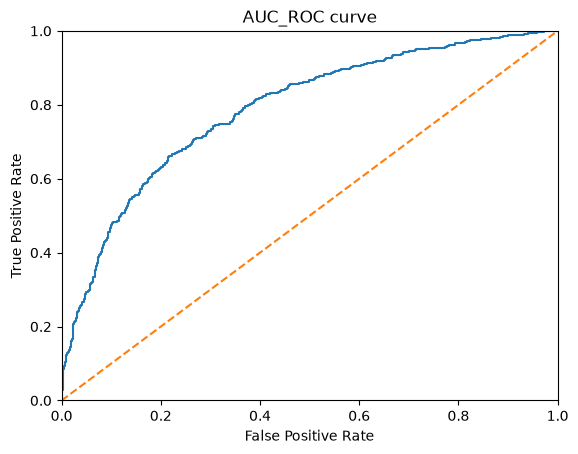

In [16]:
fpr, tpr, thresholds = roc_curve(target_valid, probabilities_one_valid)
plt.figure()

plt.plot(fpr, tpr)
# ROC curve for random model (looks like a straight line)
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('AUC_ROC curve')
plt.show()

     The AUC-ROC score here is approximately 0.787509, this is a moderate outcome for our model but not sufficient for this project.  The Receiver Operating Characteristic Curve or ROC curve (solid line) is compared to a model that makes random predictions in a diagonal line (dashed line) going from the lower left to the upper right.  The Area Under Curve or AUC  is a number that shows how much this model differs from the random model.  As shown in the graph, this model performs better than the random model, but is still not strong enough for the model.  
     The F1 score shown above is designed to balance precision and recall by use of a harmonic mean.  The score is from 0 to 1 - the closer the score is to zero the worse the model is and the closer to 1 the model is the better.  This model has an F1 score of ~.32, which is not useful at all.  As mentioned above, the model is likely leaning heavily toward predicting 'stayed' and is missing almost all of the churned accounts. This shows the model has learned something useful about ranking customers by churn risk, but its default decision threshold is poorly suited to an imbalanced dataset.  

In [17]:
#creating a new model with balanced classes
cw_model = LogisticRegression(class_weight='balanced')
cw_model.fit(features_train_scaled, target_train)
cw_predicted_valid = cw_model.predict(features_valid_scaled)
print(f1_score(target_valid, cw_predicted_valid))

0.5113043478260869


 I used the same Logistic Regression model with a class_weight= 'balanced' to adjust for the imbalance in the data.  This setting makes the data more like a 50/50 dataset, but the result was an F1 score of 0.511304 - still below the 0.59 required by the project.

In [18]:
#Upsampling data in a function
def upsample(features_train, target_train, repeat):
    features_zeros = features_train[target_train == 0]
    features_ones = features_train[target_train ==1]
    target_zeros = target_train[target_train == 0]
    target_ones = target_train[target_train == 1]

    features_upsampled = pd.concat([features_zeros] + [features_ones]* repeat)
    target_upsampled = pd.concat([target_zeros] + [target_ones] * repeat)
    features_upsampled, target_upsampled, = shuffle(features_upsampled, target_upsampled, random_state=12345)

    return features_upsampled, target_upsampled

In [19]:
features_upsampled, target_upsampled = upsample(features_train_scaled, target_train, 3)
model_upsampled = LogisticRegression(random_state=12345)
model_upsampled.fit(features_upsampled, target_upsampled)
predicted_upsampled = model_upsampled.predict(features_valid_scaled)
print('F1:', f1_score(target_valid, predicted_upsampled))

F1:

 0.5353535353535354


/workspace/.mlvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


The upsampled model was done using the validation dataset and produced an F1 score of 0.535354, which is well below the required 0.59 though slightly better than the other models.  I even took an opportunity to modify the model parameters by changing the value used for repeat from 4 to 3, 5, 6, and 8.  Using 3 produced the best F1 score, so I used 3 in the code above.  The other numbers produced a lower F1 score, in fact, the F1 score decreased with each change.  This tells me the best F1 score I can get with this model is 0.535354 and to get a higher F1 score I will have to use a different model.  For the next part of this project, I will use a Decision Tree Classifier.

In [20]:
#using a Decision Tree classifier with unbalanced data
tree_model_unbalanced = DecisionTreeClassifier(random_state=12345)
tree_model_unbalanced.fit(features_train, target_train)
tree_predicted_unbalanced_valid = tree_model_unbalanced.predict(features_valid)
print("F1:", f1_score(target_valid, tree_predicted_unbalanced_valid))

F1: 0.49821215733015495


In [21]:
#Using a Decision Tree Classifier with class_weight='balanced'
tree_model = DecisionTreeClassifier(class_weight='balanced',random_state=12345)
tree_model.fit(features_train, target_train)
tree_predicted_valid = tree_model.predict(features_valid)
print("F1:", f1_score(target_valid, tree_predicted_valid))

F1: 0.4963325183374083


These two Decision Tree Classifier models have F1 scores of 0.498212 and 0.496333, which are lower than the last two regression models and well below the required 0.59 F1 score.  The first Decision Tree Classifier was done with unbalanced data and the second Decision Tree Classifier was done with Class_weight='balanced' to account for the unbalanced data.

In [22]:
#Using a Random Forest Classifier
forest_model = RandomForestClassifier(class_weight='balanced',random_state=12345)
forest_model.fit(features_train, target_train)
forest_predicted_valid = forest_model.predict(features_valid)
print("F1:", f1_score(target_valid, forest_predicted_valid))

F1: 0.6086956521739131


The Random Forest Classifier with class_weight='balanced' showed a clear improvement from the last model with an F1 score of 0.608696, which is above the 0.59 threshold.  However, this model uses default hyperparameters, so I will try another random forest classifier in another cell with additional hyperparameters added.

In [23]:
#Using a loop to tune hyperparameters for a Random Forest Classifier Model
best_f1 = 0
best_depth = 0
best_est = 0

for depth in range(1, 11):
    for est in range(10, 101, 10):
        model = RandomForestClassifier(max_depth=depth, n_estimators=est, random_state=12345)
        model.fit(features_train, target_train)
        predicted_valid = model.predict(features_valid)
        f1 = f1_score(target_valid, predicted_valid)
        
        if f1 > best_f1:
            best_f1 = f1
            best_depth = depth
            best_est = est

print("Best max_depth:", best_depth)
print("Best n_estimators:", best_est)
print("Best F1:", best_f1)

Best max_depth: 10
Best n_estimators: 100
Best F1: 0.5705024311183144


For this model, I trained it on the non-upsampled data and created a loop to identify the best max_depth and n_estimators number.  The loop shows that the best max_depth is 10 and the best n_estimators is 100 for this model.  The F1 score for this model is 0.570502.  This is lower than the last model and is still below the 0.59 threshold required for this project.

In [24]:
#Using a new loop to tune hyperparameters for a Random Forest Classifier Model 
#using upsampled data
best_f1_upsampled = 0
best_depth_upsampled = 0
best_est_upsampled = 0

for depth in range(1, 11):
    for est in range(10, 101, 10):
        model_upsampled = RandomForestClassifier(max_depth=depth, n_estimators=est, random_state=12345)
        model_upsampled.fit(features_upsampled, target_upsampled)
        predicted_valid_upsampled = model_upsampled.predict(features_valid)
        f1 = f1_score(target_valid, predicted_valid_upsampled)
        
        if f1 > best_f1_upsampled:
            best_f1_upsampled = f1
            best_depth_upsampled = depth
            best_est_upsampled = est

print("Best max_depth:", best_depth_upsampled)
print("Best n_estimators:", best_est_upsampled)
print("Best F1:", best_f1_upsampled)

Best max_depth: 5
Best n_estimators: 40
Best F1: 0.6111111111111112


For this model I used upsampled data and used a loop to identify the best max_depth and n_estimators.  The loop shows that the best max_depth is 5 and the best n_estimators is 40 and produce an f1 Score of 0.611, which satisfies the requirements of this project.  Next I will calculate the auc_roc for this model.

In [25]:
#calculating auc_roc
probabilities_forest_model = model_upsampled.predict_proba(features_valid)
probabilities_forest_valid = probabilities_forest_model[:,1]
forest_auc_roc = roc_auc_score(target_valid, probabilities_forest_valid)
print(forest_auc_roc)

0.8037382528907953


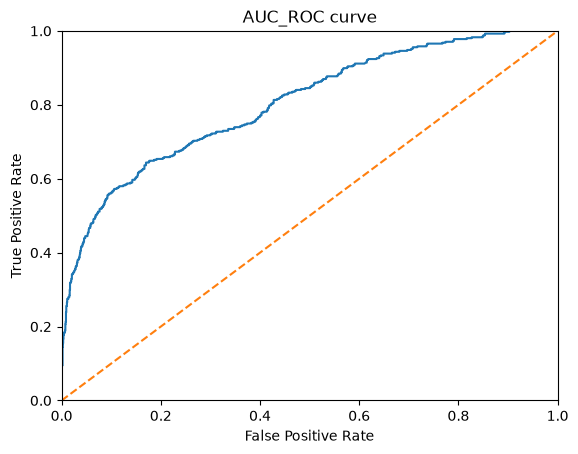

In [26]:
fpr, tpr, thresholds = roc_curve(target_valid, probabilities_forest_valid)
plt.figure()

plt.plot(fpr, tpr)
# ROC curve for random model (looks like a straight line)
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('AUC_ROC curve')
plt.show()

 The Random Forest Classifier model with a loop to identify the best max_depth, n_estimators, and was trained on upsampled data to address class imbalance has an F1 score of 0.6111 and an auc_roc() of 0.803738.  This means there is a moderate balance between precision and recall, which is sufficient to satisfy the requirements of this project. 

In [27]:
#Running this model on the test data using upsampled data and the max_depth 
#n_estimators found in the loop from the previous model on the test data
forest_model_upsampled_test = RandomForestClassifier(max_depth=5, n_estimators=40,random_state=12345)
forest_model_upsampled_test.fit(features_upsampled, target_upsampled)
forest_predicted_valid = forest_model_upsampled_test.predict(features_test)
print("F1:", f1_score(target_test, forest_predicted_valid))

F1: 0.6214285714285714


In [28]:
#calculating auc_roc
probabilities_forest_model_upsampled_test = forest_model_upsampled_test.predict_proba(features_test)
probabilities_forest_test = probabilities_forest_model_upsampled_test[:,1]
forest_auc_roc = roc_auc_score(target_test, probabilities_forest_test)
print(forest_auc_roc)

0.8439456405558101


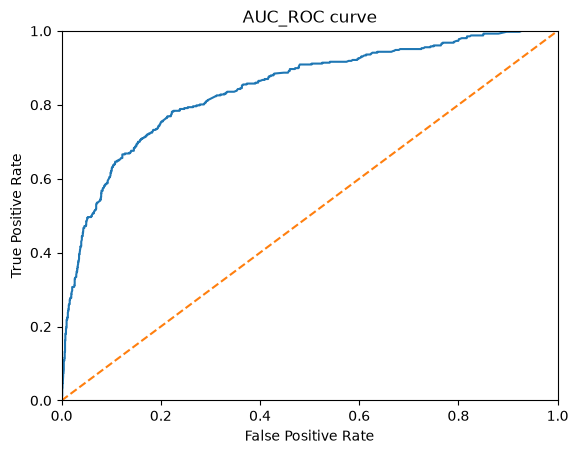

In [29]:
fpr, tpr, thresholds = roc_curve(target_test, probabilities_forest_test)
plt.figure()
plt.plot(fpr, tpr)
# ROC curve for random model (looks like a straight line)
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('AUC_ROC curve')
plt.show()

     The models I used were Logistic Regression models, a Decision Tree Classifier, and a Random Forest classifier.  The first logistic regression model was done to achieve a baseline F1 score on the unbalanced data, which was ~0.09.  Then, I had to use StandardScaler() to put the Balance, EstimatedSalary, and CreditScore columns on a similar scale.  If those columns were not on a similar scale, it could confuse the model.
     The second Logistic Regression Model did not have methods to address class imbalances, but StandardScaler() was used on the Balance, EstimatedSalary, and CreditScore columns to place the data from those columns on a comparable scale.  The F1 score for this model was 0.32, well below the 0.59 threshold.  
       The third logistic regression model was with class_weight = 'balanced' to address the class imbalance in the data.  The f1 score of that model was 0.511304, an improvement from the first logistic regression model, but not enough for this project.  
      For the fourth logistic regression model I used upsampling to address the imbalanced dataset.  The f1 score for this model was 0.535354, which is higher than the last logistic regression model and below the threshold for this project.  
     The fifth model was a decision tree classifier with nothing done to address the class imbalance in the data.  The f1 score for this model was 0.4982121, which is not better than the last logistic regression model and below the requirements of this project.
     The sixth model was a decision tree classifier with class_weight='balanced' to address the class imbalance of the data.  The f1 score for this model was 0.496333; slightly lower than the last model and still below the 0.59 threshold for this project.
     The seventh model was a random forest classifier with the class_weight set to balanced to address the class imbalance in the data.  The 0.608696 F1 score is better than any of the other models so far and is above the 0.59 threshold, but this model used default hyperparameters.
     The eighth model was another random forest classifier with a loop to look for the best max_depth and n_estimators.  The f1 score for this model was 0.5705024, the best max_depth was 10, and the best n_estimator was 100 for this model.  This model's f1 score was lower than the seventh model and below the 0.59 threshold for this project.
     The ninth model also used a loop for the best max_depth and n_estimators and was trained using upsampled data to address class imbalances.  The f1 score was 0.61111, the best max_depth was 5 and the best n_estimators was 40 for this model.  This model's f1 score satisfies the 0.59 threshold for this project.  This model's auc_roc score of 0.803738 shows it can rank positive cases above negative cases across every possible decision threshold, much better than the default 0.5 cutoff.
     The next step was to use the test data on model nine to confirm it can predict the outcome with an f1 score of at least 0.59.  I used upsampling on the training data as in model 9, set the max_depth = 5, and the n_estimators = 40.  This model produced an F1 score of 0.621428 when given the test data, which satisfies the requirements of this project.  The auc_roc for this model on the test data was 0.8439456.